# EDA: Public Perception of Flock Cameras

## Research questions 
- **RQ1 (attention):** How has public attention to Flock cameras in Illinois changed over time, and which events line up with the spikes?
- **RQ2 (attention vs. opposition):** Does Flock attention move with *opposition* activity (DeFlock) or with general surveillance interest (facial recognition, camera surveillance)?
- **RQ3 (opinion):** How does opinion of Flock differ across political groups, and is Flock viewed more negatively than public security cameras in general?

## Datasets
| Role | Dataset | Files | Measures |
|---|---|---|---|
| **Primary** | Google Trends, Illinois, monthly Nov 2021 – Nov 2026 | `time_series_*` | Search **attention**, relative 0–100 |
| **Primary** | Navigator Research national survey, Sept 2026 (n = 1,000 registered voters) | `navigator_flock_sept2026.csv` (transcribed from the published PDF) | **Opinion** of Flock specifically |
| Secondary | YouGov daily poll, Oct 2022 (national adults) | `yougov_poll_data.csv` | Feelings about **generic** public security cameras |
| Secondary | Google Trends regional and related queries | `by_region_*`, `searched_with_*` | Where people search, and what they search for |

## Outline
1. Load · 2. Dataset profiles · 3. Anomalies · 4. Cleaning (writes `data/processed/`) · 5. Distributions · 6. Relationships (so what / what next) · 7. Research questions revisited

## 1. Setup and loading

In [1]:
import glob
import os
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = "../../data/raw"   # path from notebooks/EDA M4/ to the raw data
OUT_DIR = os.path.join(os.path.dirname(os.path.normpath(DATA_DIR)), "processed")
FIG_DIR = "../../figures/eda"  # PNG copies of key figures, referenced by EDA.md
assert os.path.abspath(OUT_DIR) != os.path.abspath(DATA_DIR), "OUT_DIR points at raw!"
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 10})

def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name), bbox_inches="tight", dpi=150)

In [2]:
# Files this notebook WRITES. Skip them if they ever end up in raw/, so data isn't counted twice.
PROCESSED_NAMES = {"trends_monthly_IL", "yougov_clean", "navigator_percent", "navigator_net_scores"}

def short_name(path):
    name = os.path.basename(path).replace(".csv", "")
    return re.sub(r"^[0-9a-f]{8}-", "", name)   # drop upload hash prefixes, if present

def file_kind(name):
    for prefix, kind in [("time_series", "trends_time_series"), ("by_region", "trends_by_region"),
                         ("searched_with_rising", "trends_rising_queries"),
                         ("searched_with_top", "trends_top_queries")]:
        if name.startswith(prefix):
            return kind
    if "yougov" in name:
        return "yougov_poll"
    if "navigator" in name:
        return "navigator_survey"
    return "other"

dfs, kinds, skipped = {}, {}, []
for path in sorted(glob.glob(os.path.join(DATA_DIR, "*.csv"))):
    name = short_name(path)
    if name in PROCESSED_NAMES or name.endswith("_parsed"):
        skipped.append(name)
        continue
    dfs[name] = pd.read_csv(path)
    kinds[name] = file_kind(name)

print("looking in:", os.path.abspath(DATA_DIR))
print("loaded", len(dfs), "files; skipped processed files:", skipped)
inventory = pd.DataFrame({
    "file": list(dfs), "kind": [kinds[n] for n in dfs],
    "rows": [d.shape[0] for d in dfs.values()], "cols": [d.shape[1] for d in dfs.values()],
    "columns": [", ".join(d.columns) for d in dfs.values()],
}).sort_values(["kind", "file"]).reset_index(drop=True)
inventory

looking in: /home/claude/flock_eda/repo/data/raw
loaded 14 files; skipped processed files: []


,file,kind,rows,cols,columns
0,navigator_flock_sept2026,navigator_survey,113,5,"question, group, response, pct, value_type"
1,by_region_US-IL_20211108-2357_20261108-2357,trends_by_region,10,4,"Region, flock camera, camera surveillance, Fac..."
2,by_region_US-IL_20211109-0007_20261109-0007,trends_by_region,10,3,"Region, deflock, ban flock cameras"
3,by_region_US-IL_20211109-0012_20261109-0012,trends_by_region,10,4,"Region, facial recognition, red light camera, ..."
4,searched_with_rising-searches_queries_US-IL_20...,trends_rising_queries,50,3,"query, search interest, increase percent"
5,searched_with_rising-searches_queries_US-IL_20...,trends_rising_queries,50,3,"query, search interest, increase percent"
6,time_series_US-IL_20211027-1117_20261027-1117,trends_time_series,61,4,"Time, flock camera, camera surveillance, Facia..."
7,time_series_US-IL_20211108-2357_20261108-2357,trends_time_series,61,4,"Time, flock camera, camera surveillance, Facia..."
8,time_series_US-IL_20211109-0007_20261109-0007,trends_time_series,61,3,"Time, deflock, ban flock cameras"
9,time_series_US-IL_20211109-0012_20261109-0012,trends_time_series,0,4,"Time, facial recognition, red light camera, Su..."


## 2. Dataset profiles
Each file gets its shape, a first look at the rows, a schema (dtype, nulls, unique values), and `describe()`. Notes on what stands out in each primary dataset follow the output.

In [3]:
def profile(name, df):
    print("=" * 100)
    print(f"{name}   [{kinds[name]}]   shape = {df.shape}")
    print("=" * 100)
    if df.empty:
        print("!! EMPTY FILE: header only, no data rows")
        return
    display(df.head(3))
    display(pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "non_null": df.notna().sum(),
        "nulls": df.isna().sum(),
        "null_%": (df.isna().mean() * 100).round(1),
        "n_unique": df.nunique(),
    }))
    display(df.describe(include="all").T)

order = ["trends_time_series", "navigator_survey", "yougov_poll", "trends_by_region",
         "trends_top_queries", "trends_rising_queries", "other"]
for k in order:
    for name in [n for n in dfs if kinds[n] == k]:
        profile(name, dfs[name])

time_series_US-IL_20211027-1117_20261027-1117   [trends_time_series]   shape = (61, 4)


,Time,flock camera,camera surveillance,Facial recognition system
0,2021-11-01,0,3,8
1,2021-12-01,0,2,6
2,2022-01-01,0,1,7


,dtype,non_null,nulls,null_%,n_unique
Time,str,61,0,0.0,61
flock camera,int64,61,0,0.0,14
camera surveillance,int64,61,0,0.0,7
Facial recognition system,int64,61,0,0.0,14


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Time,61,61,2021-11-01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
flock camera,61.0,NaN,NaN,NaN,5.42623,16.42707,0.0,0.0,1.0,1.0,100.0
camera surveillance,61.0,NaN,NaN,NaN,2.213115,1.379792,1.0,1.0,2.0,2.0,8.0
Facial recognition system,61.0,NaN,NaN,NaN,8.606557,3.68003,5.0,6.0,7.0,9.0,23.0


time_series_US-IL_20211108-2357_20261108-2357   [trends_time_series]   shape = (61, 4)


,Time,flock camera,camera surveillance,Facial recognition system
0,2021-11-01,0,3,8
1,2021-12-01,0,2,6
2,2022-01-01,0,1,7


... (42 outputs left out)

searched_with_rising-searches_queries_US-IL_20211108-2358_20261108-2358   [trends_rising_queries]   shape = (50, 3)


,query,search interest,increase percent
0,image recognition ai,2,Breakout
1,when did facial recognition start,2,Breakout
2,snapchat lawsuit,2,Breakout


,dtype,non_null,nulls,null_%,n_unique
query,str,50,0,0.0,50
search interest,int64,50,0,0.0,8
increase percent,str,50,0,0.0,10


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
query,50,50,image recognition ai,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
search interest,50.0,NaN,NaN,NaN,1.52,2.40102,0.0,0.0,1.0,2.0,13.0
increase percent,50,10,Breakout,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**What stands out**

| Dataset | Shape | Types | Missing | Stands out |
|---|---|---|---|---|
| Trends time series (`flock camera`, `camera surveillance`, `Facial recognition system`) | 61 × 4 | `Time` is a string (needs parsing), the rest are int | 0 | `flock camera` is 0 or 1 for almost 4 years, then jumps to 100 in Aug 2026. The median (1) is far below the mean (5.4). |
| Trends time series (`deflock`, `ban flock cameras`) | 61 × 3 | same | 0 | `deflock` doesn't exist before Nov 2025. `ban flock cameras` is non-zero in **one** month only. |
| Trends time series (`facial recognition`, `red light camera`, `Surveillance`) | **0 × 4** | – | – | Empty export (header only) |
| Navigator | 113 × 5 | `pct` is int but mixes units | 0 | `pct` holds percentages **and** net scores (−47 to +35). 8 values are derived. Each question has a different set of groups. |
| YouGov | 100 × 10 | `published`, `conducted`, `n_adults` are all-null float | 300 cells | Only one poll and one question. `raw_pct` = `pct`. The "All" group repeats in every category. |
| Trends by region | 10 × 3–4 | int | 0 | Each row sums to 100, so the values are **shares between the compared terms**, not interest levels |
| Trends related queries | 12–50 × 3 | `increase percent` is a **string** | 0 | Mixes `"Breakout"` with text like `"4,700%"` |

## 3. Anomalies
Each anomaly is detected in code, with the number of rows it affects and what was done about it.

In [4]:
log = []
def add(file, anomaly, rows, total, action):
    log.append({"file": file, "anomaly": anomaly, "rows_affected": rows, "total_rows": total, "action": action})

for name, df in dfs.items():
    k, n = kinds[name], len(df)
    if df.empty:
        add(name, "Empty file (header only)", 0, 0, "Excluded. Re-export from Google Trends.")
        continue
    if k == "trends_time_series":
        for c in df.columns.drop("Time"):
            z = int((df[c] == 0).sum())
            if z / n > 0.8:
                add(name, f"'{c}' is 0 in most months (term barely searched)", z, n,
                    "Kept. Excluded from correlations as a near-constant series." if z / n > 0.95
                    else "Kept. Correlations restricted to 2025+ so zero-inflation doesn't drive them.")
        lt1 = int(df.astype(str).eq("<1").sum().sum())
        if lt1:
            add(name, "Trends '<1' text values", lt1, n, "Replaced with 0.5")
    if k == "trends_by_region":
        add(name, "Values are shares across the compared terms (each row sums to 100)", n, n,
            "Interpreted as relative shares. Only compared within a region.")
        out = int((~df["Region"].str.contains("IL")).sum())
        if out:
            add(name, "Regions outside Illinois (IN/MO media markets that overlap IL)", out, n,
                "Kept and labeled")
        num = df.drop(columns="Region")
        if (num.std() < 1).any():
            add(name, "Almost no variance across regions", n, n, "Not used for comparisons")
    if k in ("trends_top_queries", "trends_rising_queries"):
        br = int(df["increase percent"].astype(str).str.lower().eq("breakout").sum())
        txt = int(df["increase percent"].astype(str).str.contains("%").sum())
        add(name, f"'increase percent' mixes 'Breakout' ({br}) with text percentages ({txt})", br + txt, n,
            "Parsed to numeric increase_pct plus an is_breakout flag")
    if k == "yougov_poll":
        nulls = [c for c in df.columns if df[c].isna().all()]
        add(name, f"All-null columns: {nulls}", n, n,
            "Poll date taken from the poll URL (2022-10-18). n is unknown, so no significance tests.")
        add(name, "raw_pct identical to pct", int((df["raw_pct"] == df["pct"]).sum()), n, "raw_pct dropped")
        rep = int(((df["group"] == "All") & (df["category"] != "All adults")).sum())
        add(name, "'All' rows repeated inside every category", rep, n, "Removed (kept once, under 'All adults')")
    if k == "navigator_survey":
        add(name, "pct mixes net scores (can be negative) with percentages",
            int(df["response"].str.startswith("Net").sum()), n, "Split into navigator_percent / navigator_net_scores")
        add(name, "Values derived (unfavorable = favorable − net), not printed in the PDF",
            int((df["value_type"] == "derived").sum()), n, "Kept, flagged in value_type, and checked against the PDF")

# Duplicate exports: same columns and >80% identical rows
names = [n for n in dfs if not dfs[n].empty]
dups = set()
for i, a in enumerate(names):
    for b in names[i + 1:]:
        if list(dfs[a].columns) == list(dfs[b].columns):
            same = len(dfs[a].merge(dfs[b], how="inner"))
            if same / max(len(dfs[a]), len(dfs[b])) > 0.8:
                add(b, f"Duplicate of '{a}'", same, len(dfs[b]), "Dropped (the first file is kept)")
                dups.add(b)

anomalies = pd.DataFrame(log)
anomalies

,file,anomaly,rows_affected,total_rows,action
0,by_region_US-IL_20211108-2357_20261108-2357,Values are shares across the compared terms (e...,10,10,Interpreted as relative shares. Only compared ...
1,by_region_US-IL_20211108-2357_20261108-2357,Regions outside Illinois (IN/MO media markets ...,3,10,Kept and labeled
2,by_region_US-IL_20211109-0007_20261109-0007,Values are shares across the compared terms (e...,10,10,Interpreted as relative shares. Only compared ...
3,by_region_US-IL_20211109-0007_20261109-0007,Regions outside Illinois (IN/MO media markets ...,3,10,Kept and labeled
4,by_region_US-IL_20211109-0007_20261109-0007,Almost no variance across regions,10,10,Not used for comparisons
5,by_region_US-IL_20211109-0012_20261109-0012,Values are shares across the compared terms (e...,10,10,Interpreted as relative shares. Only compared ...
6,by_region_US-IL_20211109-0012_20261109-0012,Regions outside Illinois (IN/MO media markets ...,3,10,Kept and labeled
7,navigator_flock_sept2026,pct mixes net scores (can be negative) with pe...,19,113,Split into navigator_percent / navigator_net_s...
8,navigator_flock_sept2026,Values derived (unfavorable = favorable − net)...,8,113,"Kept, flagged in value_type, and checked again..."
9,searched_with_rising-searches_queries_US-IL_20...,'increase percent' mixes 'Breakout' (50) with ...,50,50,Parsed to numeric increase_pct plus an is_brea...


**Notes**
- **Different normalization per file (all Trends):** each Trends export is scaled 0–100 on its own, so levels can't be compared across files. Correlation doesn't depend on scale, so correlating series from different files is still valid.
- **Mixed populations (surveys):** Navigator covers U.S. registered voters in 2026. YouGov covers U.S. adults in 2022. Neither is Illinois-only. They're compared in §6.3 only as *direction*, not as a measured change.
- **Transcription:** `navigator_flock_sept2026.csv` was transcribed by hand from the Navigator PDF. Support + oppose + not sure = 100 in every party group, and every net score matches its components (checked below).

In [5]:
nav_raw = dfs["navigator_flock_sept2026"]
p = nav_raw[nav_raw.question == "police_use"].pivot(index="group", columns="response", values="pct")
print("police_use totals:", (p["Support"] + p["Oppose"] + p["Not sure"]).to_dict())
print("net = support - oppose:", ((p["Support"] - p["Oppose"]) == p["Net support"]).all())

police_use totals: {'Democrats': 100, 'Independents': 100, 'MAGA Republicans': 100, 'Non-MAGA Republicans': 100, 'Overall': 100}
net = support - oppose: True


## 4. Cleaning → `data/processed/`

In [6]:
# 4a. Join all Trends time series into one monthly table (empty files and duplicates skipped).
#     If a term appears in more than one export, keep the version with the highest peak (best resolution).
series = {}
for name in [n for n in dfs if kinds[n] == "trends_time_series" and not dfs[n].empty and n not in dups]:
    df = dfs[name].copy()
    df["Time"] = pd.to_datetime(df["Time"])
    df = df.set_index("Time").replace("<1", 0.5).apply(pd.to_numeric, errors="coerce")
    for c in df.columns:
        key = c.lower()
        if key not in series or df[c].max() > series[key].max():
            series[key] = df[c]
trends = pd.DataFrame(series).sort_index()
print(trends.shape)
trends.tail(4)

(61, 5)


,flock camera,camera surveillance,facial recognition system,deflock,ban flock cameras
Time,,,,,
2026-08-01,100,4,9,100,0
2026-09-01,44,3,8,30,0
2026-10-01,21,2,8,13,0
2026-11-01,14,2,7,12,0


In [7]:
# 4b. Related-query files: parse 'increase percent'
def parse_increase(v):
    v = str(v).strip()
    return np.nan if v.lower() == "breakout" else float(v.replace(",", "").replace("%", ""))

queries = {}
for name in [n for n in dfs if kinds[n] in ("trends_top_queries", "trends_rising_queries") and n not in dups]:
    q = dfs[name].copy()
    q["is_breakout"] = q["increase percent"].astype(str).str.lower().eq("breakout")
    q["increase_pct"] = q["increase percent"].map(parse_increase)
    queries[name] = q
    print(f"{name:72s} top query: {q['query'].iloc[0]!r}")

searched_with_rising-searches_queries_US-IL_20211108-2357_20261108-2357  top query: 'flock camera map'
searched_with_rising-searches_queries_US-IL_20211108-2358_20261108-2358  top query: 'image recognition ai'
searched_with_top-searches_queries_US-IL_20211108-2358_20261108-2358     top query: 'camera for surveillance'
searched_with_top-searches_queries_US-IL_20211109-0008_20261109-0008     top query: 'deflock map'


In [8]:
# 4c. YouGov: drop repeated 'All' rows and redundant columns; add the poll date from the URL
yg = dfs["yougov_poll_data"].copy()
yg = yg[~((yg["group"] == "All") & (yg["category"] != "All adults"))]
yg["conducted"] = pd.to_datetime(yg["poll_url"].str.extract(r"/(\d{8})-")[0], format="%Y%m%d")
yg = yg.drop(columns=["published", "n_adults", "raw_pct"])
answer_order = ["Safer", "Neither safer nor less safe", "Less safe", "Not sure"]
yg["answer"] = pd.Categorical(yg["answer"], categories=answer_order, ordered=True)

# 4d. Navigator: split percentages from net scores
nav = nav_raw.copy()
nav["unit"] = np.where(nav["response"].str.startswith("Net"), "net_score", "percent")
nav_pct = nav[nav["unit"] == "percent"].copy()
nav_net = nav[nav["unit"] == "net_score"].copy()
print("YouGov rows:", len(yg), "| Navigator percent rows:", len(nav_pct), "| net-score rows:", len(nav_net))

# 4e. Write processed files
trends.to_csv(os.path.join(OUT_DIR, "trends_monthly_IL.csv"))
yg.to_csv(os.path.join(OUT_DIR, "yougov_clean.csv"), index=False)
nav_pct.to_csv(os.path.join(OUT_DIR, "navigator_percent.csv"), index=False)
nav_net.to_csv(os.path.join(OUT_DIR, "navigator_net_scores.csv"), index=False)
for name, q in queries.items():
    q.to_csv(os.path.join(OUT_DIR, f"{name}_parsed.csv"), index=False)
print("saved to:", os.path.abspath(OUT_DIR))

YouGov rows: 80 | Navigator percent rows: 94 | net-score rows: 19
saved to: /home/claude/flock_eda/repo/data/processed


## 5. Distributions
These cover the features that matter for the RQs: the monthly Trends series (RQ1, RQ2), the Navigator opinion values (RQ3), the YouGov answers (RQ3), and the intent behind related searches (RQ1).

In [9]:
def shape_stats(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return pd.Series({"n": len(s), "mean": s.mean(), "median": s.median(), "std": s.std(),
                      "IQR": iqr, "min": s.min(), "max": s.max(), "skew": s.skew(),
                      "outliers_1.5IQR": int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
                      "share_zero": (s == 0).mean()})

trend_stats = trends.apply(shape_stats).T.round(2)
trend_stats

,n,mean,median,std,IQR,min,max,skew,outliers_1.5IQR,share_zero
flock camera,61.0,5.43,1.0,16.43,1.0,0.0,100.0,4.41,13.0,0.49
camera surveillance,61.0,2.21,2.0,1.38,1.0,1.0,8.0,2.32,7.0,0.00
facial recognition system,61.0,8.61,7.0,3.68,3.0,5.0,23.0,2.11,6.0,0.00
deflock,61.0,5.64,0.0,18.64,0.0,0.0,100.0,4.06,10.0,0.84
ban flock cameras,61.0,0.08,0.0,0.64,0.0,0.0,5.0,7.81,1.0,0.98


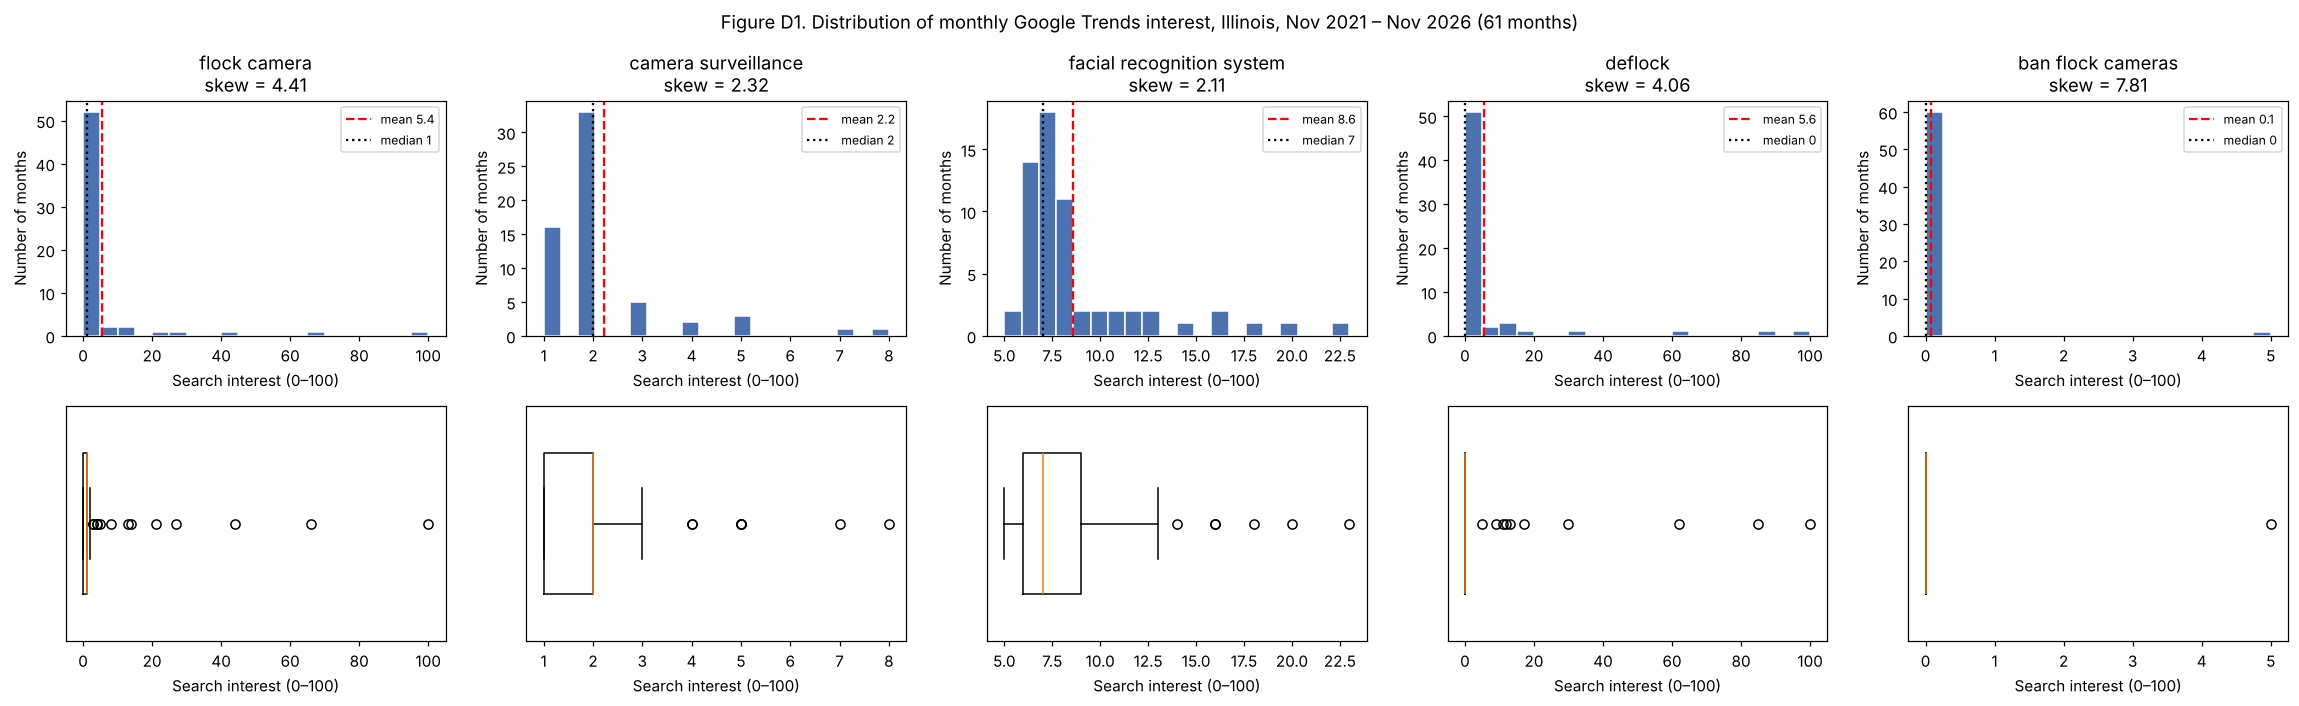

In [10]:
cols = list(trends.columns)
fig, axes = plt.subplots(2, len(cols), figsize=(4.2 * len(cols), 6.5), squeeze=False)
for i, c in enumerate(cols):
    s = trends[c].dropna()
    axes[0, i].hist(s, bins=20, color="#4C72B0", edgecolor="white")
    axes[0, i].axvline(s.mean(), color="red", ls="--", label=f"mean {s.mean():.1f}")
    axes[0, i].axvline(s.median(), color="black", ls=":", label=f"median {s.median():.0f}")
    axes[0, i].set(title=f"{c}\nskew = {s.skew():.2f}", xlabel="Search interest (0–100)", ylabel="Number of months")
    axes[0, i].legend(fontsize=8)
    axes[1, i].boxplot(s, orientation="horizontal", widths=0.6)
    axes[1, i].set(xlabel="Search interest (0–100)", yticks=[])
fig.suptitle("Figure D1. Distribution of monthly Google Trends interest, Illinois, Nov 2021 – Nov 2026 (61 months)")
fig.tight_layout()
save(fig, "D1_trends_distributions.png")
plt.show()

**Shape (Figure D1).** The Flock-related series are **extremely right-skewed and zero-inflated**. `flock camera` is 0 in 30 of 61 months (median 1, mean 5.4, skew 4.4). `deflock` is 0 in 51 months (skew 4.1). In both, the "outliers" are the 2026 surge, which is **the signal, not error**, so they're kept and summarized with median/IQR rather than mean/SD. `ban flock cameras` is non-zero in a single month (skew 7.8), too sparse to analyze. The general-surveillance terms are different: `facial recognition system` (median 7) and `camera surveillance` (median 2) have a stable non-zero baseline with only mild right skew (about 2). Most of the time, people in Illinois search for general surveillance terms more than for Flock. Flock attention is **event-driven**.

intent analysis uses: searched_with_rising-searches_queries_US-IL_20211108-2357_20261108-2357


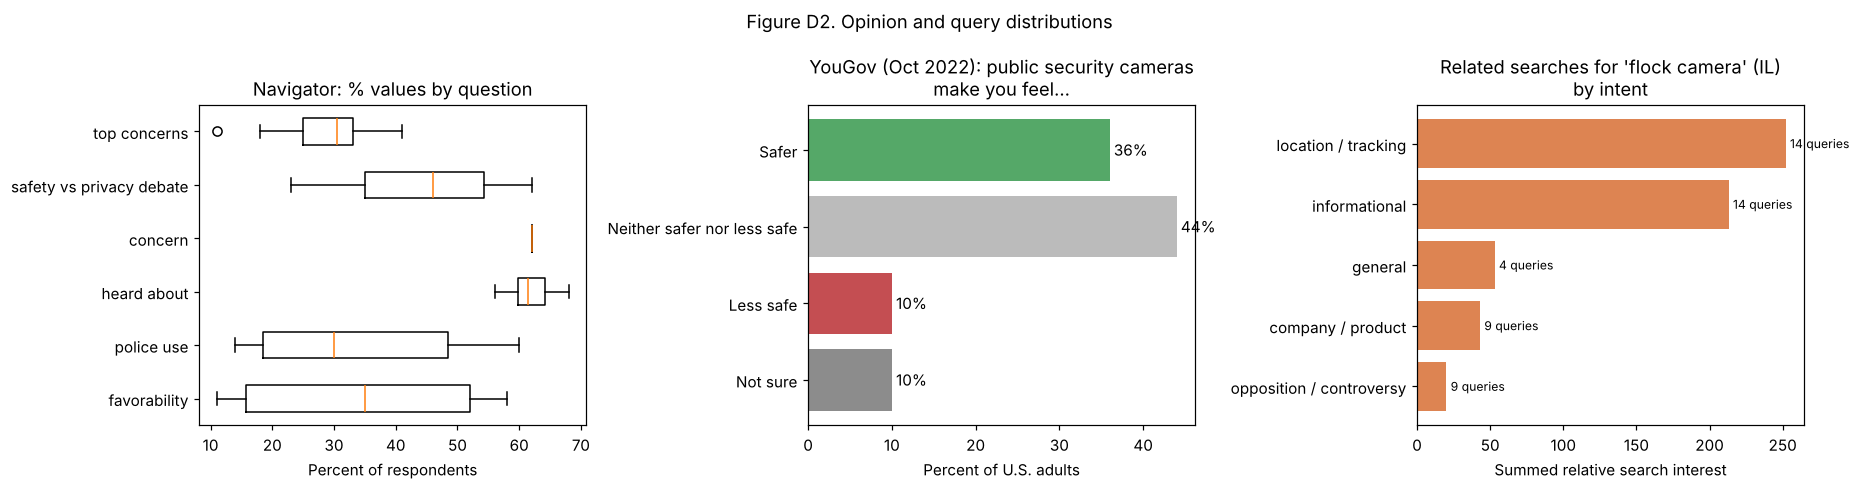

,n_queries,total_interest
intent,,
opposition / controversy,9,20
company / product,9,43
general,4,53
informational,14,213
location / tracking,14,252


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# Navigator: spread of % values within each question (percent rows only)
qs = nav_pct["question"].unique()
axes[0].boxplot([nav_pct.loc[nav_pct.question == q, "pct"] for q in qs], orientation="horizontal",
                tick_labels=[q.replace("_", " ") for q in qs])
axes[0].set(title="Navigator: % values by question", xlabel="Percent of respondents")

# YouGov: overall answer distribution
overall = yg[yg.category == "All adults"].set_index("answer")["pct"].reindex(answer_order)
axes[1].barh(overall.index.astype(str), overall.values, color=["#55A868", "#BBBBBB", "#C44E52", "#8C8C8C"])
axes[1].invert_yaxis()
axes[1].set(title="YouGov (Oct 2022): public security cameras\nmake you feel...", xlabel="Percent of U.S. adults")
for y, v in enumerate(overall.values):
    axes[1].text(v + 0.5, y, f"{v:.0f}%", va="center")

# Related-query intent (flock camera seed): counts of queries by type
intent_rules = {
    "opposition / controversy": r"deflock|de flock|ban|lawsuit|controversy|4th amendment|ceo|langley|reddit",
    "location / tracking": r"map|near me|location|lookup|tracker|search|database|live feed",
    "informational": r"what|meaning|purpose|do |does|look like|used for",
    "company / product": r"company|stock|login|app|system|safety|replacement|alpr|axon",
}
classify = lambda q: next((lab for lab, pat in intent_rules.items() if re.search(pat, q)), "general")
# pick the related-query export whose queries mention "flock camera" most (the flock camera seed term)
seed = max(queries, key=lambda n: queries[n]["query"].str.contains("flock camera").sum())
print("intent analysis uses:", seed)
fq = queries[seed].copy()
fq["intent"] = fq["query"].map(classify)
intent = fq.groupby("intent")["search interest"].agg(n_queries="count", total_interest="sum").sort_values("total_interest")
axes[2].barh(intent.index, intent["total_interest"], color="#DD8452")
axes[2].set(title="Related searches for 'flock camera' (IL)\nby intent", xlabel="Summed relative search interest")
for y, (v, k) in enumerate(zip(intent["total_interest"], intent["n_queries"])):
    axes[2].text(v + 3, y, f"{k} queries", va="center", fontsize=8)

fig.suptitle("Figure D2. Opinion and query distributions")
fig.tight_layout()
save(fig, "D2_opinion_query_distributions.png")
plt.show()
intent

**Shape (Figure D2).**
- **Navigator:** `police_use` values are bimodal. Oppose is 40–60% and support is 19–46%, which shows a split *between groups*, not a spread within one. `top_concerns` values are tightly clustered (about 11–41%), so no single concern dominates. `heard_about` is high and tight (56–68%), meaning most people are aware of Flock.
- **YouGov:** the distribution is centered on **neutral**. 44% say "neither safer nor less safe", 36% "safer", and only 10% "less safe". In 2022, generic public cameras weren't polarizing.
- **Query intent:** related searches are dominated by **location** (14 queries, total interest 252) and **informational** (14 queries, 213) searches. Opposition searches are a small tail (9 queries, 20). The distribution is right-skewed: two "map" queries alone account for 200 of the 581 total interest points. Intent labels come from keyword rules and were checked by hand.

## 6. Relationships
Three relationship figures, one for each research question. Each joins or compares at least two datasets.

### 6.1 Figure R1. Attention over time, with event and survey dates (RQ1)

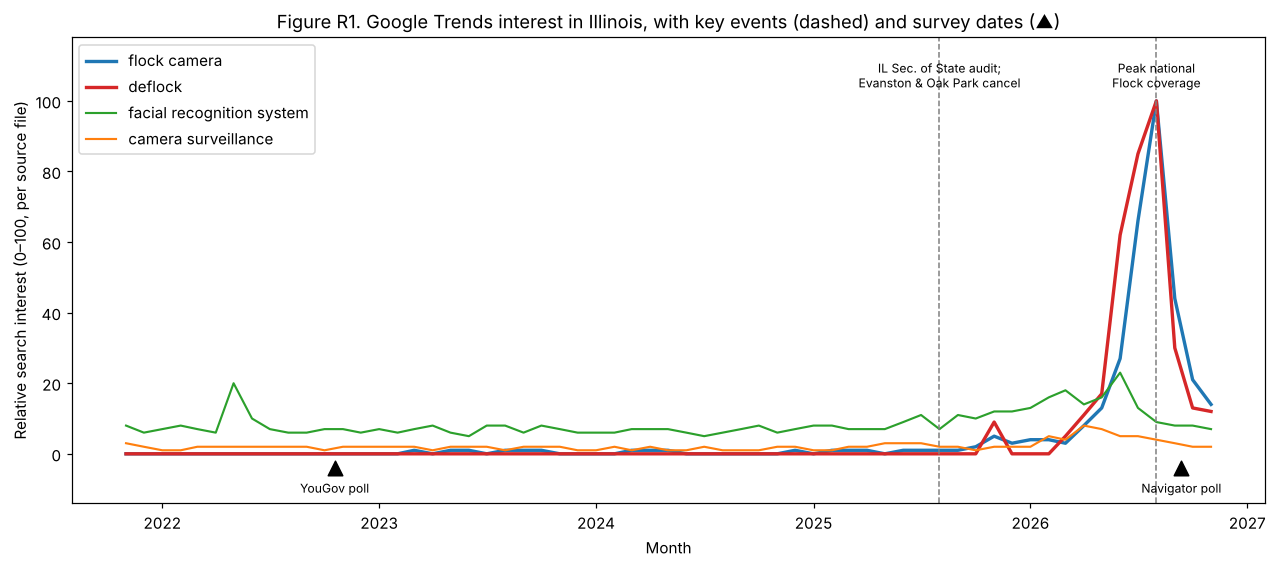

first non-zero month: {'flock camera': '2023-03-01', 'deflock': '2025-11-01', 'facial recognition system': '2021-11-01', 'camera surveillance': '2021-11-01'}
flock camera mean before Aug 2025: 0.33 | from Aug 2025: 19.75


In [12]:
events = {
    "2025-08-01": "IL Sec. of State audit;\nEvanston & Oak Park cancel",
    "2026-08-01": "Peak national\nFlock coverage",
}
surveys = {"2022-10-18": "YouGov poll", "2026-09-12": "Navigator poll"}
plot_cols = [c for c in ["flock camera", "deflock", "facial recognition system", "camera surveillance"] if c in trends]
colors = {"flock camera": "#1f77b4", "deflock": "#d62728", "facial recognition system": "#2ca02c",
          "camera surveillance": "#ff7f0e"}

fig, ax = plt.subplots(figsize=(14, 5.5))
for c in plot_cols:
    ax.plot(trends.index, trends[c], label=c, lw=2.2 if "flock" in c else 1.4, color=colors.get(c))
for d, lab in events.items():
    ax.axvline(pd.Timestamp(d), color="gray", ls="--", lw=1)
    ax.text(pd.Timestamp(d), 103, lab, fontsize=8, ha="center", va="bottom")
for d, lab in surveys.items():
    ax.scatter(pd.Timestamp(d), -4, marker="^", s=90, color="black", zorder=5, clip_on=False)
    ax.text(pd.Timestamp(d), -11, lab, fontsize=8, ha="center")
ax.set(ylim=(-14, 118), ylabel="Relative search interest (0–100, per source file)", xlabel="Month",
       title="Figure R1. Google Trends interest in Illinois, with key events (dashed) and survey dates (▲)")
ax.legend(loc="upper left")
save(fig, "R1_attention_timeline.png")
plt.show()

print("first non-zero month:", {c: str(trends[c][trends[c] > 0].index.min().date()) for c in plot_cols})
print("flock camera mean before Aug 2025:", round(trends.loc[:'2025-07-01', 'flock camera'].mean(), 2),
      "| from Aug 2025:", round(trends.loc['2025-08-01':, 'flock camera'].mean(), 2))

**So what?** Attention to Flock in Illinois was essentially zero until late 2025. The mean was 0.3 before Aug 2025 and 19.8 after. It rose from April 2026, peaked in **August 2026**, and by November had fallen back to 14% of the peak. The August 2025 Illinois audit and suburban cancellations caused only a small bump. The big surge came a year later with national coverage. `deflock` (opposition) rose **with** and slightly **ahead of** `flock camera`, while `facial recognition system` and `camera surveillance` stayed flat. For RQ1, this means Flock awareness is new, sudden, and tied to news events rather than a slow rise in surveillance concern. It also places the **Navigator poll (Sept 2026) right after the peak**, so its opinions were measured at maximum public attention. The YouGov poll (2022) was taken before Flock was on anyone's radar.

**What next?** *Did news coverage drive the surge, or the other way around?* Pull GDELT daily article volume and tone for "Flock Safety" and test whether coverage comes before search interest. Also re-export Trends at **weekly** resolution for 2026 to date the peak to specific stories.

### 6.2 Figure R2. Does Flock attention move with opposition or with general surveillance interest? (RQ2)

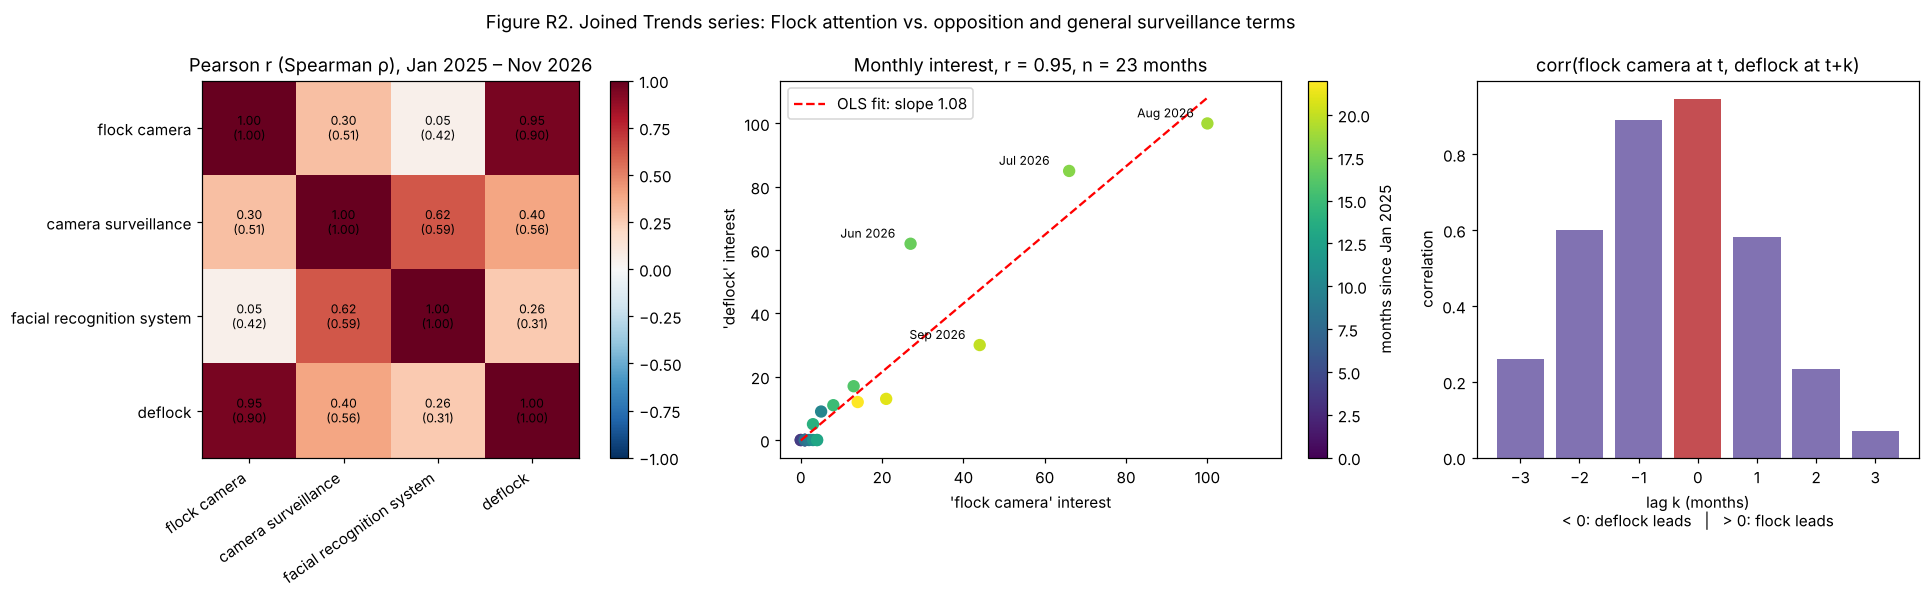

,flock camera,camera surveillance,facial recognition system,deflock
flock camera,1.00,0.30,0.05,0.95
camera surveillance,0.30,1.00,0.62,0.40
facial recognition system,0.05,0.62,1.00,0.26
deflock,0.95,0.40,0.26,1.00


-3    0.26
-2    0.60
-1    0.89
0     0.95
1     0.58
2     0.23
3     0.07
dtype: float64

In [13]:
recent = trends.loc["2025-01-01":]
recent = recent.loc[:, recent.std() > 0]
use = [c for c in recent.columns if (recent[c] == 0).mean() < 0.95]   # drop near-constant series
pear = recent[use].corr(method="pearson")
spear = recent[use].corr(method="spearman")

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), gridspec_kw={"width_ratios": [1.1, 1, 0.8]})
im = axes[0].imshow(pear, cmap="RdBu_r", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(use)), use, rotation=35, ha="right")
axes[0].set_yticks(range(len(use)), use)
for i in range(len(use)):
    for j in range(len(use)):
        axes[0].text(j, i, f"{pear.iloc[i, j]:.2f}\n({spear.iloc[i, j]:.2f})", ha="center", va="center", fontsize=8)
axes[0].set_title("Pearson r (Spearman ρ), Jan 2025 – Nov 2026")
fig.colorbar(im, ax=axes[0], fraction=0.046)

x, y = "flock camera", "deflock"
d = recent[[x, y]].dropna()
sc = axes[1].scatter(d[x], d[y], c=np.arange(len(d)), cmap="viridis", s=50)
m, b = np.polyfit(d[x], d[y], 1)
xs = np.linspace(0, d[x].max(), 50)
axes[1].set_xlim(-5, 118)
axes[1].plot(xs, m * xs + b, "r--", label=f"OLS fit: slope {m:.2f}")
for t, row in d[(d[x] >= 25) | (d[y] >= 25)].iterrows():
    axes[1].annotate(t.strftime("%b %Y"), (row[x], row[y]), fontsize=8, xytext=(-46, 4), textcoords="offset points")
axes[1].set(xlabel="'flock camera' interest", ylabel="'deflock' interest",
            title=f"Monthly interest, r = {d[x].corr(d[y]):.2f}, n = {len(d)} months")
axes[1].legend()
fig.colorbar(sc, ax=axes[1], fraction=0.046, label="months since Jan 2025")

lags = range(-3, 4)
lag_corr = pd.Series({k: d[x].corr(d[y].shift(-k)) for k in lags})
axes[2].bar(lag_corr.index, lag_corr.values, color=["#8172B2" if k != lag_corr.idxmax() else "#C44E52" for k in lags])
axes[2].set(xlabel="lag k (months)\n< 0: deflock leads   |   > 0: flock leads", ylabel="correlation",
            title="corr(flock camera at t, deflock at t+k)")
fig.suptitle("Figure R2. Joined Trends series: Flock attention vs. opposition and general surveillance terms")
fig.tight_layout()
save(fig, "R2_correlations.png")
plt.show()
display(pear.round(2)); lag_corr.round(2)

**So what?** Flock attention moves almost one-to-one with **opposition** searches (`deflock`: Pearson r = 0.95, Spearman ρ = 0.90). It is essentially unrelated in Pearson terms to **general surveillance** searches (`facial recognition system`: r = 0.05, `camera surveillance`: r = 0.30). The higher Spearman values for these (0.42, 0.51) show they drift up slightly in the same months, but the spike is unique to Flock. In the lag plot, the correlation is highest at lag 0, and lag −1 (0.89) is higher than lag +1 (0.58). DeFlock interest tends to rise **about a month before** general Flock interest. For example, in June 2026 deflock was at 62 while flock camera was at 27. For RQ2, this means public attention to Flock is bound up with the opposition movement and is not just part of a wider surveillance trend. When people in Illinois look Flock up, they are often also looking at the activist map. This is consistent with the "flock camera map" queries in Figure D2.

**What next?** *Is opposition activity causing awareness, or are both reacting to the same news?* n = 23 monthly points is too few for a Granger test, so use weekly 2026 Trends data together with GDELT coverage. A further question is whether places with more cameras search more: join Finding Flock / DeFlock camera counts per media market with the regional Trends shares.

### 6.3 Figure R3. Opinion by party: Flock specifically (Navigator 2026) vs. generic cameras (YouGov 2022) (RQ3)

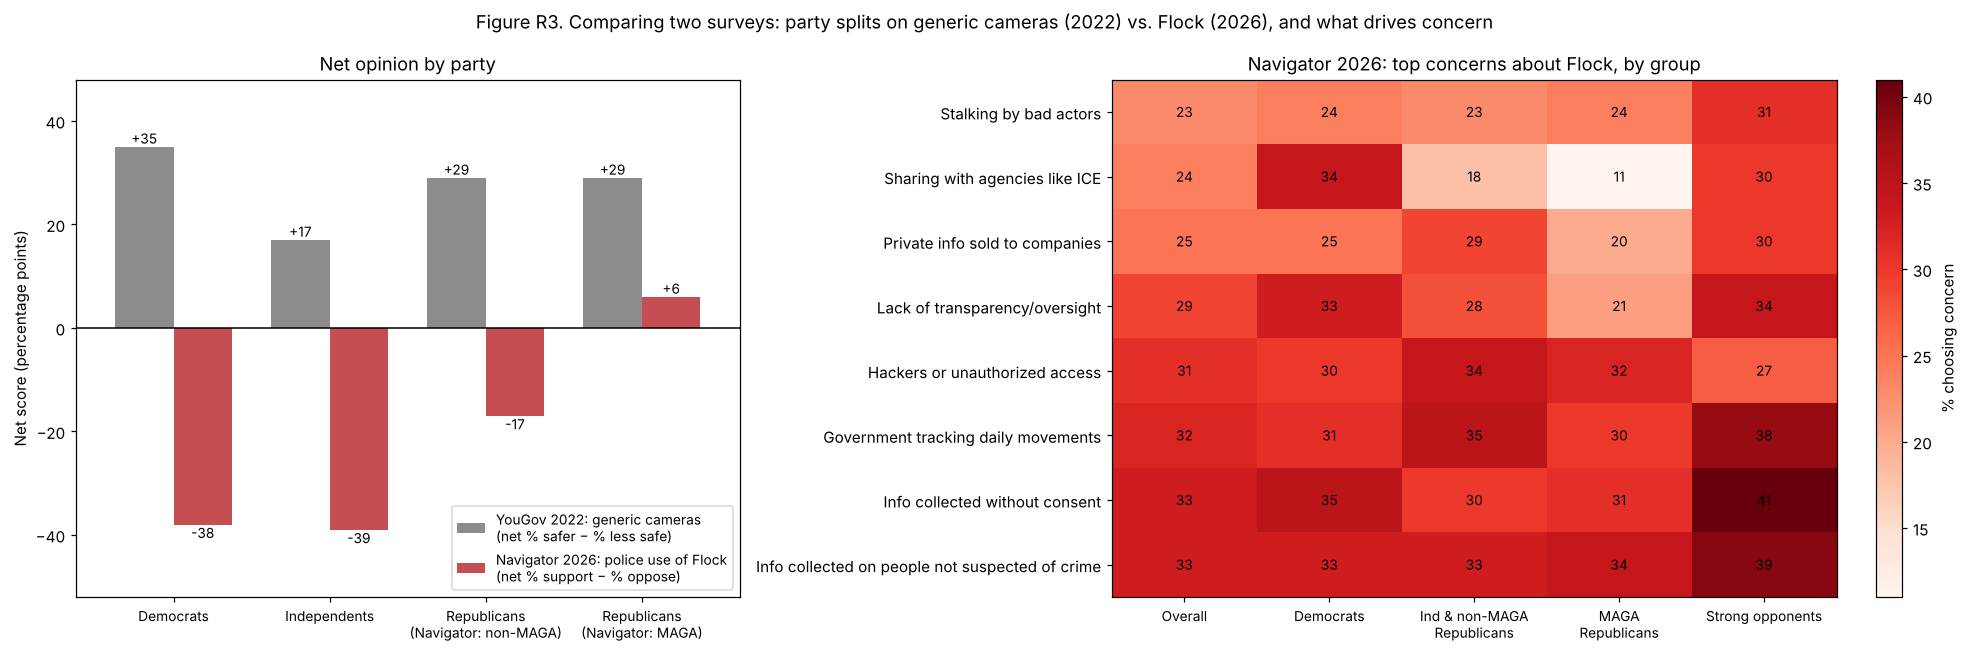

,YouGov 2022: generic cameras\n(net % safer − % less safe),Navigator 2026: police use of Flock\n(net % support − % oppose)
Democrats,35.0,-38
Independents,17.0,-39
Republicans\n(Navigator: non-MAGA),29.0,-17
Republicans\n(Navigator: MAGA),29.0,6


In [14]:
# Net score for each dataset: Navigator = % support − % oppose police use of Flock;
# YouGov = % "safer" − % "less safe" with public security cameras
yg_pol = yg[yg.category == "Politics"].pivot_table(index="group", columns="answer", values="pct", observed=False)
yg_net = (yg_pol["Safer"] - yg_pol["Less safe"]).rename({"Dem": "Democrats", "Rep": "Republicans", "Ind": "Independents"})

nv = nav_net[(nav_net.question == "police_use")].set_index("group")["pct"]
comp = pd.DataFrame({
    "YouGov 2022: generic cameras\n(net % safer − % less safe)": yg_net.reindex(
        ["Democrats", "Independents", "Republicans", "Republicans"]).values,
    "Navigator 2026: police use of Flock\n(net % support − % oppose)": nv.reindex(
        ["Democrats", "Independents", "Non-MAGA Republicans", "MAGA Republicans"]).values,
}, index=["Democrats", "Independents", "Republicans\n(Navigator: non-MAGA)", "Republicans\n(Navigator: MAGA)"])

fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [1, 1.2]})
comp.plot.bar(ax=axes[0], color=["#8C8C8C", "#C44E52"], rot=0, width=0.75)
axes[0].axhline(0, color="black", lw=1)
axes[0].set(ylabel="Net score (percentage points)", title="Net opinion by party")
for cont in axes[0].containers:
    axes[0].bar_label(cont, fmt="%+.0f", fontsize=9)
axes[0].set_ylim(-52, 48)
axes[0].tick_params(axis="x", labelsize=9)
axes[0].legend(fontsize=9, loc="lower right")

tc = nav_pct[nav_pct.question == "top_concerns"].pivot(index="response", columns="group", values="pct")
tc = tc[[c for c in ["Overall", "Democrats", "Ind & non-MAGA Republicans", "MAGA Republicans", "Strong opponents"] if c in tc]]
tc = tc.sort_values("Overall")
im = axes[1].imshow(tc, cmap="Reds", aspect="auto")
axes[1].set_xticks(range(tc.shape[1]), [c.replace(" Republicans", "\nRepublicans") for c in tc.columns], fontsize=9)
axes[1].set_yticks(range(tc.shape[0]), tc.index)
for i in range(tc.shape[0]):
    for j in range(tc.shape[1]):
        axes[1].text(j, i, f"{tc.iloc[i, j]:.0f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=axes[1], fraction=0.04, label="% choosing concern")
axes[1].set_title("Navigator 2026: top concerns about Flock, by group")
fig.suptitle("Figure R3. Comparing two surveys: party splits on generic cameras (2022) vs. Flock (2026), and what drives concern")
fig.tight_layout()
save(fig, "R3_opinion_by_party.png")
plt.show()
comp

**So what?** In 2022, every party group felt **net positive** about generic public cameras: Democrats +35, Republicans +29, Independents +17. On **Flock specifically** in 2026, every group except MAGA Republicans is **net negative**: Democrats −38, Independents −39, non-MAGA Republicans −17, MAGA Republicans +6. The partisan order **flips**. Democrats were the *most* positive about generic cameras and are among the *most* negative about Flock. The heatmap helps explain why. Concerns about collecting data on non-suspects, consent, and tracking are shared across parties (about 30–35% in every group). But **sharing with ICE** splits sharply: 34% of Democrats vs 11% of MAGA Republicans. Transparency and oversight show a smaller version of the same gap (33% vs 21%). For RQ3, this means Flock is viewed far more negatively than "cameras" in general. The difference is driven by concerns specific to Flock's data sharing, especially immigration enforcement, which links to the 2025 Illinois audit finding in Figure R1.

**Caveat:** the two surveys differ in wording (feel safer vs support police use), population (adults vs registered voters), and year. YouGov's file has no sample size, so this is a **directional comparison, not a significance test**.

## 7. Research questions revisited

**Original question:** *"What is the public perception of Flock cameras in Chicago?"*

**Revised questions** (stated at the top of this notebook):
1. **RQ1:** How has *attention* to Flock in Illinois changed over time, and what events line up with spikes? *(Figure R1)*
2. **RQ2:** Does Flock attention move with *opposition* activity or with general surveillance interest? *(Figure R2)*
3. **RQ3:** How does *opinion* of Flock differ by political group, and is Flock viewed more negatively than cameras in general? *(Figure R3)*

**Why they changed**
- **Perception was split into attention vs. opinion.** Google Trends measures how much people search, not whether they approve. Surveys measure approval but only at single points in time. Treating these as two separate questions keeps each claim matched to a source that can support it.
- **Chicago became Illinois, plus national surveys.** Trends is only available at the media-market level, where "Chicago IL" covers the whole metro. Both surveys are national. No Chicago-only opinion data was found, so Chicago is now context (§6 "what next"), not the unit of analysis.
- **RQ2 was added after EDA.** The 0.95 correlation with `deflock` and the dominance of "map" queries showed that opposition activity is central to how people encounter Flock. That deserves its own question.
